Лабораторная работа №5. Работа с файлами в Linux средствами ассемблера

---



In [ ]:
import random as rd

Variant = 14
rd.seed(Variant)

Numbers_of_problems = [i+1 for i in rd.sample(range(11),2)]
print(Numbers_of_problems)


[2, 10]


2. Из заданного текстового файла (латиница) прочитать каждый k-й символ, результат записать во второй файл. Имена файлов, значение k передавать параметрами командной строки.

In [ ]:
format elf64
public _start

include '../Lab_4/funcs.asm'

section '.data' writable
    buffer rb 1 ; буфер на 1 байт для побайтового чтения/записи

section '.text' executable
    _start:
        pop rcx
        cmp rcx, 4
        jl .l1

        mov rdi, [rsp+8] ; адрес имени входного файла
        mov rax, 2 ; sys_open
        mov rsi, 0o ; O_RDONLY, только чтение
        syscall
        cmp rax, 0 ; проверяем результат открытия
        jl .l1 ; rax < 0 - ошибка открытия, завершаем работу
        mov r8, rax ; r8 = дескриптор входного файла

        mov rdi, [rsp+16] ; адрес имени выходного файла
        mov rax, 2 ; sys_open
        mov rsi, 577 ; флаги: O_WRONLY | O_CREAT | O_TRUNC
        mov rdx, 0644o ; права создаваемого файла (rw-r--r--)
        syscall
        cmp rax, 0
        jl .close_input ; ошибка - закрываем уже открытый входной файл
        mov r9, rax ; r9 = дескриптор выходного файла

        mov rsi, [rsp+24] ; адрес строки с числом k
        call func_atoi ; переводим строку в число, результат в rax
        mov rbx, rax ; rbx = k

cmp rbx, 0 ; защита от деления на ноль
je .close_both

xor r10, r10 ; r10 = счётчик прочитанных символов (позиция в файле), изначально 0

.loop_read:
    mov rax, 0 ; sys_read
    mov rdi, r8 ; rdi = дескриптор входного файла
    mov rsi, buffer ; rsi = адрес буфера, куда запишется прочитанный байт
    mov rdx, 1 ; читаем по одному байту (смещение в файле сдвигается автоматически)
    syscall ; в rax вернётся число прочитанных байт
    cmp rax, 0 ; сравниваем с 0
    jle .close_both ; rax <= 0: конец файла (EOF) или ошибка - выходим из цикла

    inc r10 ; увеличиваем номер текущего символа

    mov rax, r10 ; rax = делимое (номер символа)
    xor rdx, rdx ; обнуляем старшую часть делимого rdx:rax перед div
    div rbx ; делим на k: частное в rax, остаток в rdx
    cmp rdx, 0 ; остаток 0 - номер символа кратен k
    jne .loop_read ; остаток не 0 - символ пропускаем, читаем следующий

    mov rax, 1 ; sys_write
    mov rdi, r9 ; rdi = дескриптор выходного файла
    mov rsi, buffer ; rsi = адрес буфера с символом
    mov rdx, 1 ; rdx = записываем 1 байт
    syscall ; пишем каждый k-й символ в выходной файл
    jmp .loop_read ; возвращаемся к чтению

.close_both:
    mov rdi, r9 ; rdi = дескриптор выходного файла
    mov rax, 3 ; sys_close
    syscall ; закрываем выходной файл

.close_input:
    mov rdi, r8 ; rdi = дескриптор входного файла
    mov rax, 3
    syscall ; закрываем входной файл

.l1:
    call exit


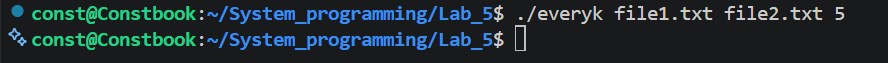
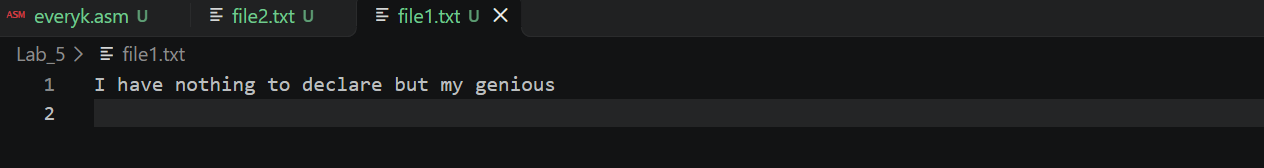
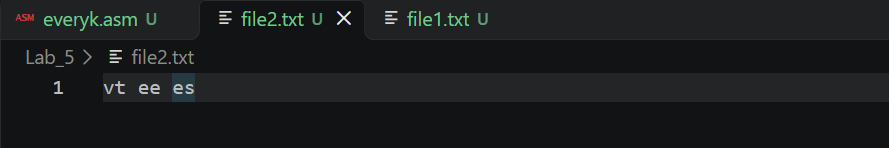

10. Для заданного текстового файла во второй файл каждое предложение (заканчивается ., !, ?) записать задом наперед. Имена файлов передавать параметрами командной строки.

In [ ]:
format elf64
public _start

include '../Lab_4/funcs.asm'

section '.data' writable
    buffer rb 1025 ; буфер для чтения (1024 байта + место под нуль-терминатор)

section '.text' executable
    _start:
        pop rcx
        cmp rcx, 3
        jl .l1

        mov rdi, [rsp+8] ; адрес имени входного файла
        mov rax, 2 ; sys_open
        mov rsi, 0o ; O_RDONLY
        syscall
        cmp rax, 0
        jl .l1 ; ошибка открытия
        mov r8, rax ; r8 = дескриптор входного файла

        mov rdi, [rsp+16] ; адрес имени выходного файла
        mov rax, 2 ; sys_open
        mov rsi, 577 ; O_WRONLY | O_CREAT | O_TRUNC
        mov rdx, 0644o ; права rw-r--r--
        syscall
        cmp rax, 0
        jl .close_input
        mov r9, rax ; r9 = дескриптор выходного файла

        xor r10, r10 ; r10 = сколько байт сейчас в буфере
        xor r14, r14 ; r14 = 1, если файл закончился

.read:
    mov rax, 0 ; sys_read
    mov rdi, r8
    mov rsi, buffer
    add rsi, r10 ; дописываем после недочитанного хвоста
    mov rdx, 1024
    sub rdx, r10 ; читаем сколько влезет в оставшееся место в буфере
    syscall
    cmp rax, 0
    jle .eof ; 0 - конец файла, <0 - ошибка
    add r10, rax ; новая длина данных в буфере
    xor r12, r12 ; r12 = начало текущего предложения
    xor r13, r13 ; r13 = позиция сканирования

.scan: ; ищем конец предложения
    cmp r13, r10
    je .scan_end ; буфер просмотрен
    mov bl, byte [buffer+r13]
    inc r13 ; r13 - позиция сразу за символом
    cmp bl, '.'
    je .flush
    cmp bl, '!'
    je .flush
    cmp bl, '?'
    je .flush
    jmp .scan

.flush: ; предложение - buffer[r12 .. r13)
    xor rbx, rbx
    mov bl, byte [buffer+r13]
    mov r15, rbx ; r15 = байт, который временно затрём нулём
    mov byte [buffer+r13], 0 ; ставим конец строки
    mov rsi, buffer
    add rsi, r12
    call reverse_string ; переворачиваем предложение
    mov rax, rsi ; rsi = адрес результата
    call len_str
    mov rdx, rax ; rdx = длина для записи
    mov rax, 1 ; sys_write
    mov rdi, r9
    syscall
    mov rbx, r15
    mov byte [buffer+r13], bl ; возвращаем затёртый байт
    mov r12, r13 ; следующее предложение начинается здесь
    cmp r14, 1
    je .close_both ; это был последний кусок файла
    jmp .scan

.scan_end: ; остался хвост buffer[r12 .. r10)
    cmp r12, 0
    je .no_shift
    mov rcx, r12 ; rcx = откуда копируем
    xor rdx, rdx ; rdx = куда копируем

.copy: ; сдвигаем хвост в начало буфера
    cmp rcx, r10
    je .copied
    mov bl, byte [buffer+rcx]
    mov byte [buffer+rdx], bl
    inc rcx
    inc rdx
    jmp .copy

.copied:
    mov r10, rdx ; длина хвоста
    jmp .read

.no_shift:
    cmp r10, 1024
    jl .read ; буфер не полон - дочитываем
    mov r13, r10 ; буфер полон, а конца предложения нет -
    jmp .flush ; выводим как есть

.eof:
    mov r14, 1 ; файл закончился
    cmp r10, 0
    je .close_both ; хвоста нет
    xor r12, r12 ; хвост с начала буфера
    mov r13, r10
    jmp .flush ; выводим последний кусок без . ! ?

.close_both:
    mov rdi, r9
    mov rax, 3 ; sys_close
    syscall

.close_input:
    mov rdi, r8
    mov rax, 3 ; sys_close
    syscall

.l1:
    call exit


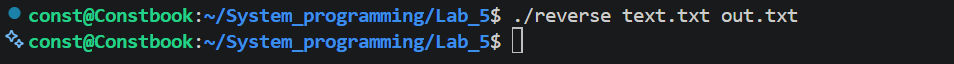
Содержимое text.txt:

Hello world. How are you today? I am fine! The quick brown fox jumps over the lazy dog. Assembly is fun, but it requires patience. Is this the end? No! There is one more sentence, and it has no closing mark

Содержимое out.txt после запуска программы:

.dlrow olleH?yadot uoy era woH !enif ma I .god yzal eht revo spmuj xof nworb kciuq ehT .ecneitap seriuqer ti tub ,nuf si ylbmessA ?dne eht siht sI !oN
kram gnisolc on sah ti dna ,ecnetnes erom eno si erehT